<a href="https://colab.research.google.com/github/Mizuchan18-glitch/Object-Detection-Using-YOLO/blob/main/YOLObut_u_copy_ur_lectures'_codes_lol.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Versi OpenCV: 4.14.0


Saving IMG20261103105656.jpg to IMG20261103105656 (1).jpg
Bentuk (tinggi, lebar, kanal): (600, 600, 3)
Tipe data: uint8
Nilai piksel kiri-atas (B, G, R): [213 213 207]


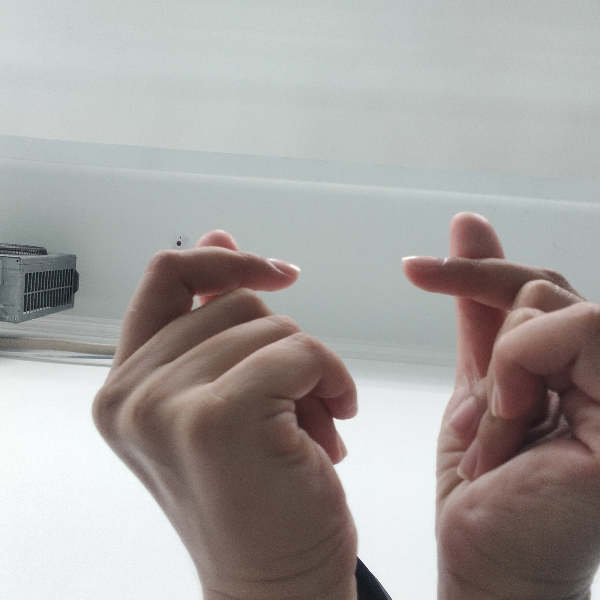

In [ ]:
# python
import cv2
import numpy as np
from google.colab import files
from google.colab.patches import cv2_imshow


print("Versi OpenCV:", cv2.__version__)


def kecilkan(gambar, lebar=600):
    tinggi = int(gambar.shape[0] * lebar / gambar.shape[1])
    return cv2.resize(gambar, (lebar, tinggi))


unggah = files.upload()                      # pilih 1 foto (dari HP/laptop)
nama = list(unggah.keys())[0]
mentah = cv2.imread(nama)                    # OpenCV membaca urutan kanal B, G, R
assert mentah is not None, "Gambar gagal dibaca - coba format JPG/PNG"
img = kecilkan(mentah)
print("Bentuk (tinggi, lebar, kanal):", img.shape)
print("Tipe data:", img.dtype)
print("Nilai piksel kiri-atas (B, G, R):", img[0, 0])
cv2_imshow(img)


In [ ]:
# Konversi gambar berwarna (3 kanal BGR) menjadi derajat keabuan / grayscale (1 kanal)


abu = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)         # hitam-putih (1 kanal)
mini = cv2.resize(abu, (8, 8), interpolation=cv2.INTER_AREA)
print(mini)                                         # 64 angka = "gambar" 8x8
print("Nilai Piksel Terenda(Gelap):", mini.min(), " Tertinggi(Ter:)", mini.max())

[[209 204 203 203 200 194 190 190]
 [203 202 201 200 195 193 190 189]
 [174 181 186 189 189 189 185 184]
 [107 161 110 141 182 162 103 163]
 [150 147  99 125 158 175 115 104]
 [245 161 116  84 132 226 103  66]
 [247 229 119  75 153 225 113  94]
 [242 241 189  82  96 212  76  81]]
Nilai Piksel Terenda(Gelap): 66  Tertinggi(Ter:) 247


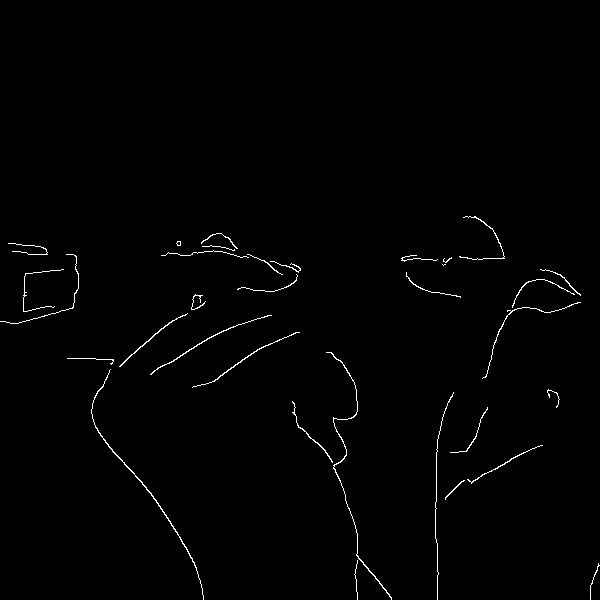

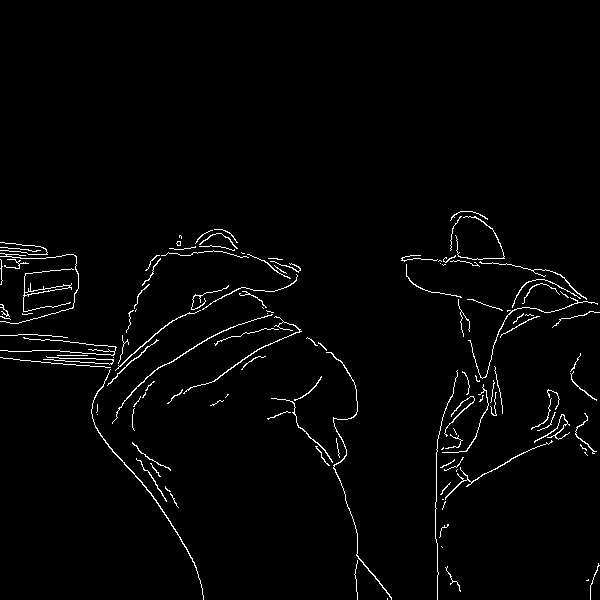

In [ ]:
# Haluskan gambar terlebih dahulu untuk meredam bintik derau (noise)
blur = cv2.GaussianBlur(abu, (5, 5), 0)


# Bandingkan deteksi tepi dengan ambang batas ketat vs. ambang batas sensitif
tepi_a = cv2.Canny(blur, 100, 200)
tepi_b = cv2.Canny(blur, 30, 80)
cv2_imshow(tepi_a)
cv2_imshow(tepi_b)



image 1/1 /content/IMG20261103105656.jpg: 640x640 2 persons, 335.5ms
Speed: 11.1ms preprocess, 335.5ms inference, 17.7ms postprocess per image at shape (1, 3, 640, 640)


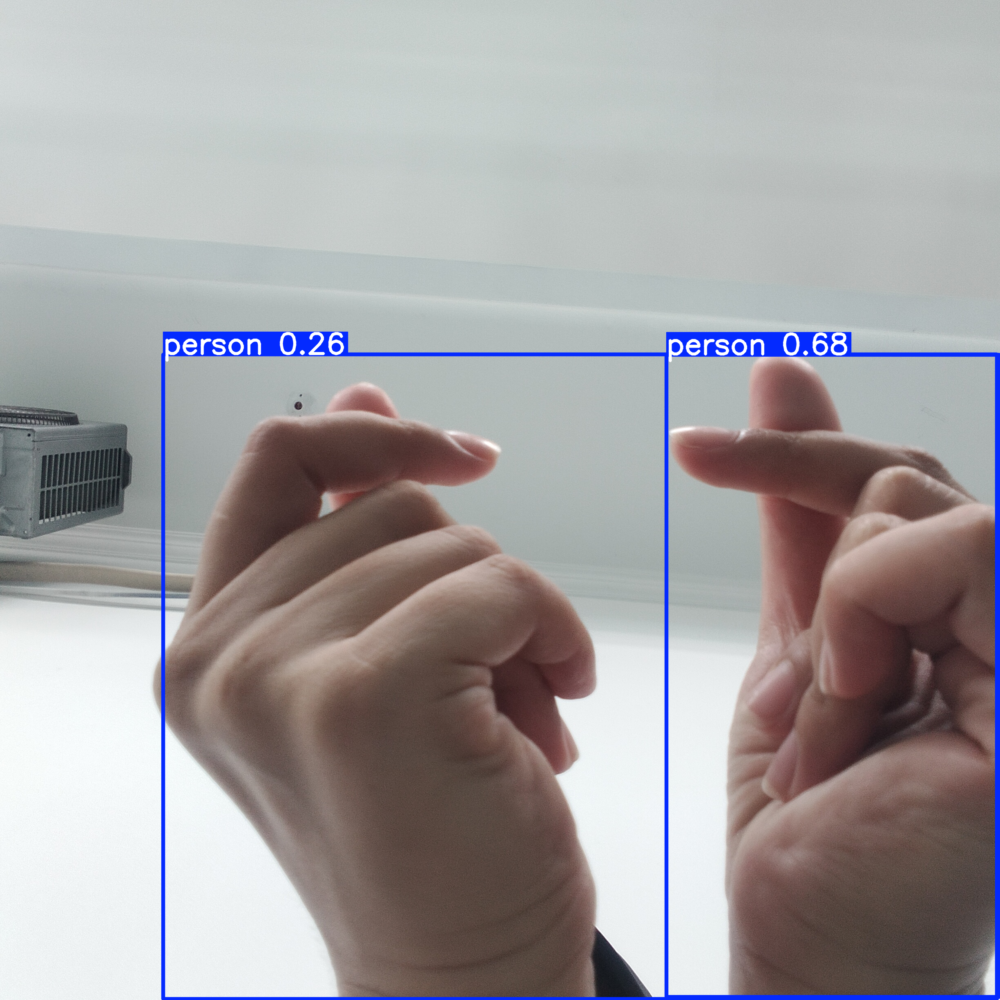

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'traffic light', 10: 'fire hydrant', 11: 'stop sign', 12: 'parking meter', 13: 'bench', 14: 'bird', 15: 'cat', 16: 'dog', 17: 'horse', 18: 'sheep', 19: 'cow', 20: 'elephant', 21: 'bear', 22: 'zebra', 23: 'giraffe', 24: 'backpack', 25: 'umbrella', 26: 'handbag', 27: 'tie', 28: 'suitcase', 29: 'frisbee', 30: 'skis', 31: 'snowboard', 32: 'sports ball', 33: 'kite', 34: 'baseball bat', 35: 'baseball glove', 36: 'skateboard', 37: 'surfboard', 38: 'tennis racket', 39: 'bottle', 40: 'wine glass', 41: 'cup', 42: 'fork', 43: 'knife', 44: 'spoon', 45: 'bowl', 46: 'banana', 47: 'apple', 48: 'sandwich', 49: 'orange', 50: 'broccoli', 51: 'carrot', 52: 'hot dog', 53: 'pizza', 54: 'donut', 55: 'cake', 56: 'chair', 57: 'couch', 58: 'potted plant', 59: 'bed', 60: 'dining table', 61: 'toilet', 62: 'tv', 63: 'laptop', 64: 'mouse', 65: 'remote', 66: 'keyboard', 67: 'cell phone', 68: 'microw

In [ ]:
!pip -q install ultralytics
from ultralytics import YOLO


model = YOLO("yolo11n.pt")               # model pretrained COCO (diunduh otomatis)
hasil = model("IMG20261103105656.jpg")         # ganti dengan berkas foto Anda
cv2_imshow(hasil[0].plot())              # plot() menghasilkan gambar BGR berkotak dan berlabel
print(model.names)                       # daftar kelas yang dikenali model

Saving IMG20261103105656.jpg to IMG20261103105656 (2).jpg
Ditemukan 12 field EXIF:

  ImageWidth: 2448
  ImageLength: 2448
  GPSInfo: 1130
  ResolutionUnit: 2
  ExifOffset: 210
  Make: OPPO
  Model: OPPO A60
  Orientation: 1
  DateTime: 2026:11:03 10:56:56
  YCbCrPositioning: 1
  XResolution: 72.0
  YResolution: 72.0

Bentuk array: (2448, 2448, 3)


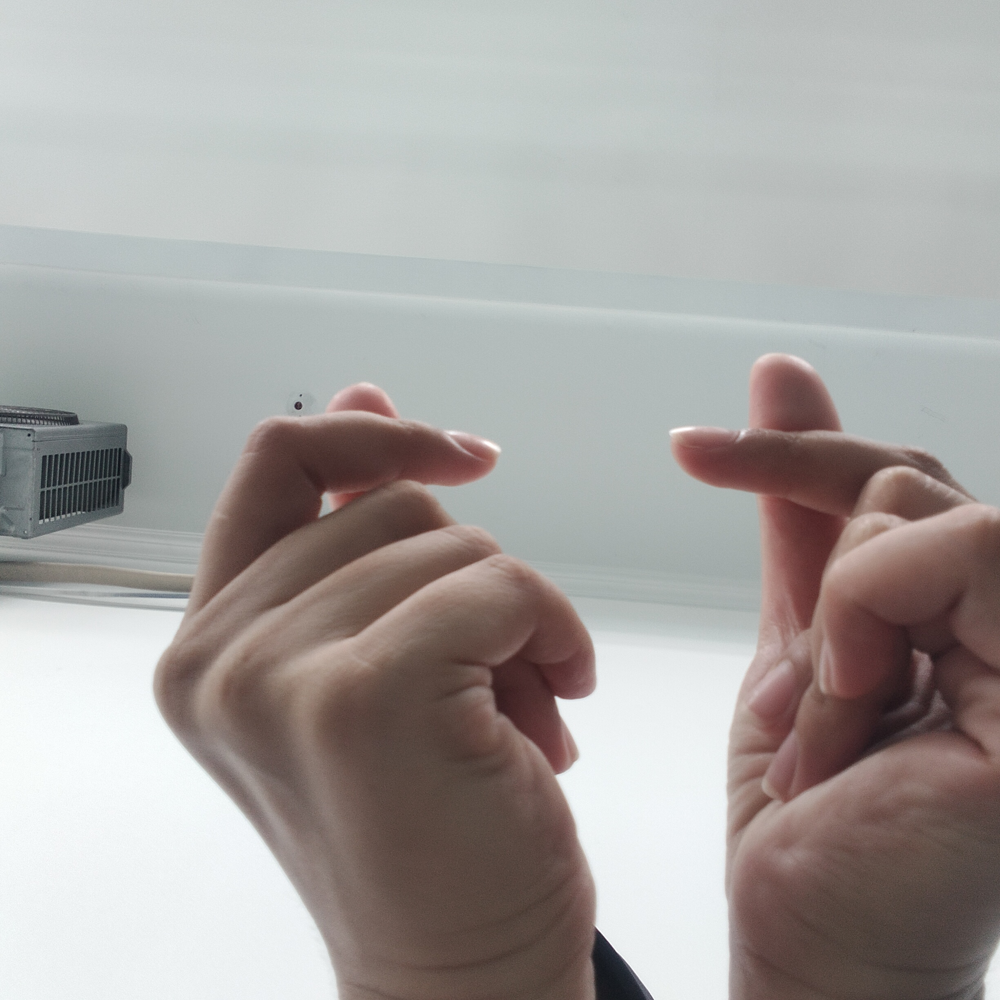

In [ ]:
from PIL import Image
from PIL.ExifTags import TAGS
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow


# --- Bagian 1: baca metadata EXIF ---
unggah = files.upload()                       # unggah SATU foto ambil langsung dari galeri HP/perangkat
nama = list(unggah.keys())[0]


img_pil = Image.open(nama)
exif_data = img_pil.getexif()


if len(exif_data) == 0:
    print("Tidak ada data EXIF ditemukan.")
    print("Kemungkinan: foto ini pernah dikirim lewat WhatsApp/media sosial")
    print("(metadata terhapus otomatis saat dikirim). Coba foto langsung dari galeri.")
else:
    print(f"Ditemukan {len(exif_data)} field EXIF:\n")
    for tag_id, value in exif_data.items():
        nama_tag = TAGS.get(tag_id, tag_id)
        print(f"  {nama_tag}: {value}")


# --- Bagian 2: baca dan tampilkan sebagai array (seperti P1, tapi data kalian sendiri) ---
img_cv = cv2.imread(nama)
print("\nBentuk array:", img_cv.shape)
cv2_imshow(img_cv)
